In [71]:
import os
import tensorflow as tf 
import numpy as np
import matplotlib.pyplot as plt
import pandas as pd

from tensorflow.keras import Sequential
from keras.layers import Dense,Flatten,Conv2D,MaxPooling2D
from tensorflow.keras.preprocessing.image import ImageDataGenerator


import warnings


In [72]:
train_path = '/kaggle/input/datasets/misrakahmed/vegetable-image-dataset/Vegetable Images/train'
test_path = '/kaggle/input/datasets/misrakahmed/vegetable-image-dataset/Vegetable Images/test'
val_path = '/kaggle/input/datasets/misrakahmed/vegetable-image-dataset/Vegetable Images/validation'

In [73]:
classes = os.listdir(train_path)

In [74]:
class_number=len(classes)

In [75]:
class_number

15

In [76]:
def count_img(path):
    counts={}
    classes=os.listdir(path)
    for i in classes:
        class_folder=path+"/"+i
        img_folder=os.listdir(class_folder)
        counts[i]=len(os.listdir(class_folder))
    return counts

train_counts=count_img(train_path)
test_counts=count_img(test_path)
val_counts=count_img(val_path)

In [77]:
print(train_counts)

{'Bean': 1000, 'Bitter_Gourd': 1000, 'Bottle_Gourd': 1000, 'Brinjal': 1000, 'Broccoli': 1000, 'Cabbage': 1000, 'Capsicum': 1000, 'Carrot': 1000, 'Cauliflower': 1000, 'Cucumber': 1000, 'Papaya': 1000, 'Potato': 1000, 'Pumpkin': 1000, 'Radish': 1000, 'Tomato': 1000}


In [78]:
df_train=pd.DataFrame(list(train_counts.items()),columns=['Vegetable','Train Count'])
df_test=pd.DataFrame(list(test_counts.items()),columns=['Vegetable','Test Count'])            
df_val=pd.DataFrame(list(val_counts.items()),columns=['Vegetable','Validation Count'])

In [79]:
merged_df=df_train.merge(df_test).merge(df_val)

In [80]:
print(merged_df)

       Vegetable  Train Count  Test Count  Validation Count
0           Bean         1000         200               200
1   Bitter_Gourd         1000         200               200
2   Bottle_Gourd         1000         200               200
3        Brinjal         1000         200               200
4       Broccoli         1000         200               200
5        Cabbage         1000         200               200
6       Capsicum         1000         200               200
7         Carrot         1000         200               200
8    Cauliflower         1000         200               200
9       Cucumber         1000         200               200
10        Papaya         1000         200               200
11        Potato         1000         200               200
12       Pumpkin         1000         200               200
13        Radish         1000         200               200
14        Tomato         1000         200               200


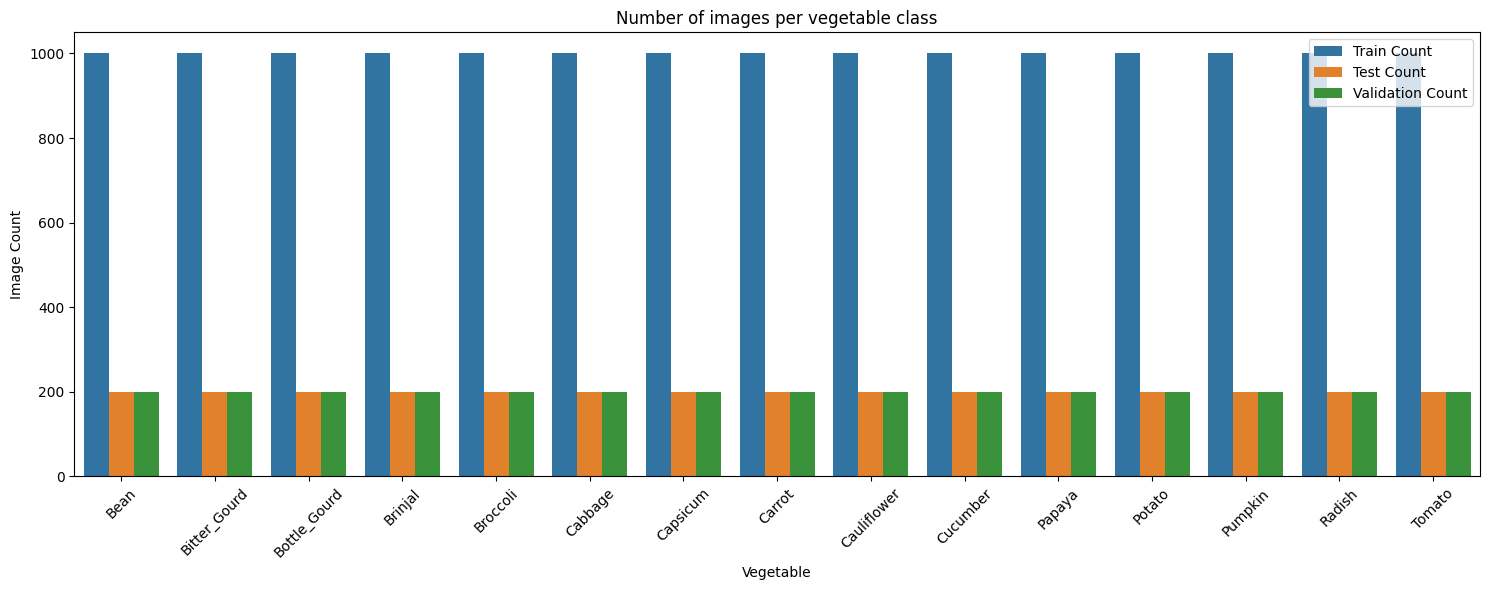

In [81]:
import matplotlib.pyplot as plt
import seaborn as sns

df_plot = merged_df.melt(
    id_vars="Vegetable",
    value_vars=["Train Count", "Test Count", "Validation Count"],
    var_name="Dataset",
    value_name="Image Count"
)

plt.figure(figsize=(15, 6))
sns.barplot(data=df_plot, x="Vegetable", y="Image Count", hue="Dataset")

plt.title("Number of images per vegetable class")
plt.xlabel("Vegetable")
plt.ylabel("Image Count")
plt.xticks(rotation=45)
plt.legend()
plt.tight_layout()

plt.show()

In [82]:
#DATASET IS BALANCED

In [94]:
gen=ImageDataGenerator()

In [97]:
train_gen = ImageDataGenerator(
    rescale=1.0 / 255.0,
    rotation_range=20,
    width_shift_range=0.2,
    height_shift_range=0.2,
    shear_range=0.2,
    zoom_range=0.2,
    horizontal_flip=True,
    validation_split=0.2,)

val_gen = ImageDataGenerator(rescale=1.0 / 255.0, validation_split=0.2)

In [102]:
train_data= train_gen.flow_from_directory(train_path,                                       
    target_size=(224,224),
    batch_size=32,
    class_mode="categorical",
    subset="training",
    seed=42,)


val_data= val_gen.flow_from_directory(train_path,                                       
    target_size=(224,224),
    batch_size=32,
    class_mode="categorical",
    subset="validation",
    seed=42,)

Found 12000 images belonging to 15 classes.
Found 3000 images belonging to 15 classes.


In [115]:
test_data=gen.flow_from_directory(test_path,
                                                  target_size=(224,224),
                                                  class_mode='categorical')

Found 3000 images belonging to 15 classes.


In [86]:
model = Sequential()

model.add(Conv2D(filters = 32,kernel_size= (3,3),activation = 'relu',input_shape=(224,224,3)))
model.add(MaxPooling2D(pool_size= (2,2)))


model.add(Conv2D(filters = 64,kernel_size= (3,3),activation = 'relu'))
model.add(MaxPooling2D(pool_size= (2,2)))


model.add(Conv2D(filters = 128,kernel_size= (3,3),activation = 'relu'))
model.add(MaxPooling2D(pool_size= (2,2)))

model.add(Flatten())
model.add(Dense(512, activation='relu'))
model.add(Dropout(0.5))
model.add(Dense(15, activation='softmax'))


In [87]:
model.compile(
    optimizer = 'adam',
    loss= 'categorical_crossentropy',
    metrics = ['accuracy']  
)

In [88]:
model.summary()

Model: "sequential_16"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━┓
┃ Layer (type)                    ┃ Output Shape           ┃       Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━┩
│ conv2d_47 (Conv2D)              │ (None, 222, 222, 32)   │           896 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ max_pooling2d_47 (MaxPooling2D) │ (None, 111, 111, 32)   │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ conv2d_48 (Conv2D)              │ (None, 109, 109, 64)   │        18,496 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ max_pooling2d_48 (MaxPooling2D) │ (None, 54, 54, 64)     │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ conv2d_49 (Conv2D)              │ (None, 52, 52, 128)    │        73,856 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ max_pooling2d_49 (MaxPooling2D) │ (None, 26, 26, 128)    │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ flatten_16 (Flatten)            │ (None, 86528)          │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_34 (Dense)                │ (None, 512)            │    44,302,848 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dropout_15 (Dropout)            │ (None, 512)            │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_35 (Dense)                │ (None, 15)             │         7,695 │
└─────────────────────────────────┴────────────────────────┴───────────────┘

 Total params: 44,403,791 (169.39 MB)

 Trainable params: 44,403,791 (169.39 MB)

 Non-trainable params: 0 (0.00 B)

In [103]:
from tensorflow.keras.callbacks import EarlyStopping
early_stopping=EarlyStopping(
monitor='val_loss',
patience=5,
restore_best_weights=True
)

model.fit(train_data,epochs=15,validation_data = val_data,callbacks=[early_stopping])


Epoch 1/15
375/375 ━━━━━━━━━━━━━━━━━━━━ 155s 414ms/step - accuracy: 0.4033 - loss: 1.8150 - val_accuracy: 0.6487 - val_loss: 1.0621
Epoch 2/15
375/375 ━━━━━━━━━━━━━━━━━━━━ 153s 408ms/step - accuracy: 0.6205 - loss: 1.1443 - val_accuracy: 0.7663 - val_loss: 0.7093
Epoch 3/15
375/375 ━━━━━━━━━━━━━━━━━━━━ 153s 407ms/step - accuracy: 0.6971 - loss: 0.9286 - val_accuracy: 0.8273 - val_loss: 0.5531
Epoch 4/15
375/375 ━━━━━━━━━━━━━━━━━━━━ 155s 413ms/step - accuracy: 0.7393 - loss: 0.8036 - val_accuracy: 0.8500 - val_loss: 0.4954
Epoch 5/15
375/375 ━━━━━━━━━━━━━━━━━━━━ 154s 411ms/step - accuracy: 0.7729 - loss: 0.7015 - val_accuracy: 0.8643 - val_loss: 0.4050
Epoch 6/15
375/375 ━━━━━━━━━━━━━━━━━━━━ 151s 402ms/step - accuracy: 0.7947 - loss: 0.6324 - val_accuracy: 0.9017 - val_loss: 0.3030
Epoch 7/15
375/375 ━━━━━━━━━━━━━━━━━━━━ 149s 398ms/step - accuracy: 0.8197 - loss: 0.5591 - val_accuracy: 0.9233 - val_loss: 0.2364
Epoch 8/15
375/375 ━━━━━━━━━━━━━━━━━━━━ 150s 398ms/step - accuracy: 0.8386 -

In [ ]:
#prevent overfitting
#saving time and compute

In [117]:
train_loss,train_accuracy=model.evaluate(train_data)
val_loss,val_accuracy=model.evaluate(val_data)

print(f"Training Accuracy: {train_accuracy}")
print(f"validation Accuracy: {val_accuracy}")

print(f"Training Loss: {train_loss}")
print(f"Validation Loss: {val_loss}")

test_loss,test_accuracy=model.evaluate(test_data)
print(f"Test Accuracy: {test_accuracy}")
print(f"Test Loss: {test_loss}")


375/375 ━━━━━━━━━━━━━━━━━━━━ 139s 371ms/step - accuracy: 0.9456 - loss: 0.1797
94/94 ━━━━━━━━━━━━━━━━━━━━ 6s 63ms/step - accuracy: 0.9503 - loss: 0.1633
Training Accuracy: 0.9455833435058594
validation Accuracy: 0.9503333568572998
Training Loss: 0.17972953617572784
Validation Loss: 0.16326546669006348
94/94 ━━━━━━━━━━━━━━━━━━━━ 167s 2s/step - accuracy: 0.3277 - loss: 555.1208
Test Accuracy: 0.32766667008399963
Test Loss: 555.1207885742188
